In [4]:
import json
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
print(f'Using scikit-learn version: {sklearn.__version__}')

Using scikit-learn version: 1.9.0


In [70]:
# --- 1. Load Dataset ---
df = pd.read_excel('/content/extention of Z-Alizadeh sani dataset.xlsx')

# --- 2. Drop Index, Leakage, and Target Columns from Feature Matrix (X) ---
index_cols = [col for col in df.columns if 'unnamed' in col.lower() or col.lower() == 'index' or col.lower() == 'id']
df = df.drop(columns=index_cols, errors='ignore')

# Drop initial clinical leakage or unneeded columns + ALL target columns so they are never used as features
targets_to_drop = ['Exertional CP', 'Obesity', 'Weight', 'DM', 'Cath', 'RCA', 'LAD', 'LCX']
df_new = df.drop(columns=targets_to_drop, errors='ignore')

# --- 3. Handle Sparse Data (Drop columns with > 40% missing values) ---
missing_fractions = df_new.isnull().mean()
sparse_columns = missing_fractions[missing_fractions > 0.40].index.tolist()
print(f"Dropping {len(sparse_columns)} excessively sparse columns (>40% missing): {sparse_columns}")
df_new = df_new.drop(columns=sparse_columns, errors='ignore')

# Map target for correlation analysis
y_cath_temp = df['Cath'].apply(
    lambda x: 1 if 'STENOTIC' in str(x).strip().upper() or str(x).strip().upper() == 'CAD' else 0
)

# --- 4. Correlation-Based Feature Pruning (Threshold = 0.4) ---
temp_corr_df = df_new.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).copy()
temp_corr_df['Target'] = y_cath_temp

correlations = temp_corr_df.corr()['Target'].abs()
weak_features = correlations[correlations < 0.03].index.tolist()
if 'Target' in weak_features:
    weak_features.remove('Target')
df_new = df_new.drop(columns=weak_features, errors='ignore')

# Strict Multicollinearity Check: Drop features with correlation > 0.40 among themselves
num_df = df_new.select_dtypes(include=['int64', 'float64', 'int32', 'float32'])
corr_matrix_full = num_df.corr().abs()
upper_tri = corr_matrix_full.where(np.triu(np.ones(corr_matrix_full.shape), k=1).astype(bool))
to_drop_collinear = [column for column in upper_tri.columns if any(upper_tri[column] > 0.40)]
print(f"Dropping {len(to_drop_collinear)} features due to strict collinearity (> 0.4): {to_drop_collinear}")
df_new = df_new.drop(columns=to_drop_collinear, errors='ignore')

# --- 5. Define Features (X) and Target Labels (y) ---
X = df_new.copy()
numeric_features = X.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# --- 6. Robust Preprocessing Pipelines for Sparse/Missing Data ---
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features),
])

print(f"Final clean feature count after all reductions: {X.shape[1]} columns remaining.")

Dropping 0 excessively sparse columns (>40% missing): []
Dropping 5 features due to strict collinearity (> 0.4): ['BP', 'St Elevation', 'BUN', 'Neut', 'Region RWMA']
Final clean feature count after all reductions: 44 columns remaining.


In [71]:
df.head(5)

,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,...,Lymph,Neut,PLT,EF-TTE,Region RWMA,VHD,LAD,LCX,RCA,Cath
0,53,90,175,Male,29.387755,0,1,1,0,0,...,39,52,261,50,0,N,Stenotic,Normal,Stenotic,CAD
1,67,70,157,Fmale,28.398718,0,1,0,0,0,...,38,55,165,40,4,N,Stenotic,Stenotic,Normal,CAD
2,54,54,164,Male,20.077335,0,0,1,0,0,...,38,60,230,40,2,mild,Stenotic,Normal,Normal,CAD
3,66,67,158,Fmale,26.838648,0,1,0,0,0,...,18,72,742,55,0,Severe,Normal,Normal,Normal,Normal
4,50,87,153,Fmale,37.165193,0,1,0,0,0,...,55,39,274,50,0,Severe,Normal,Normal,Normal,Normal


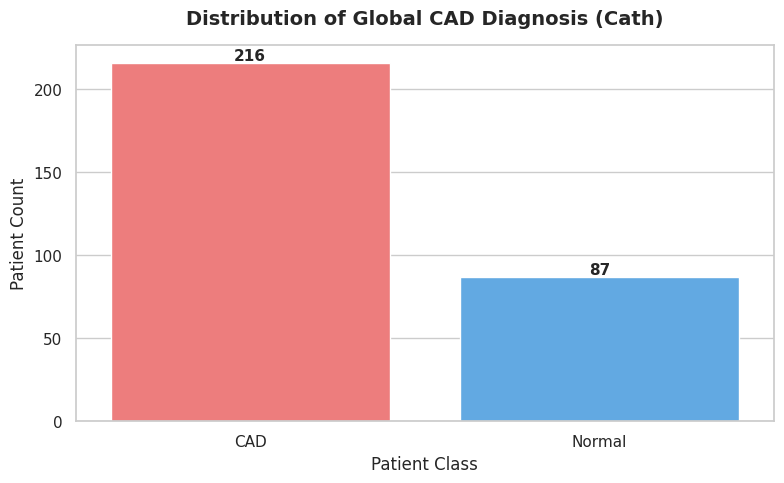

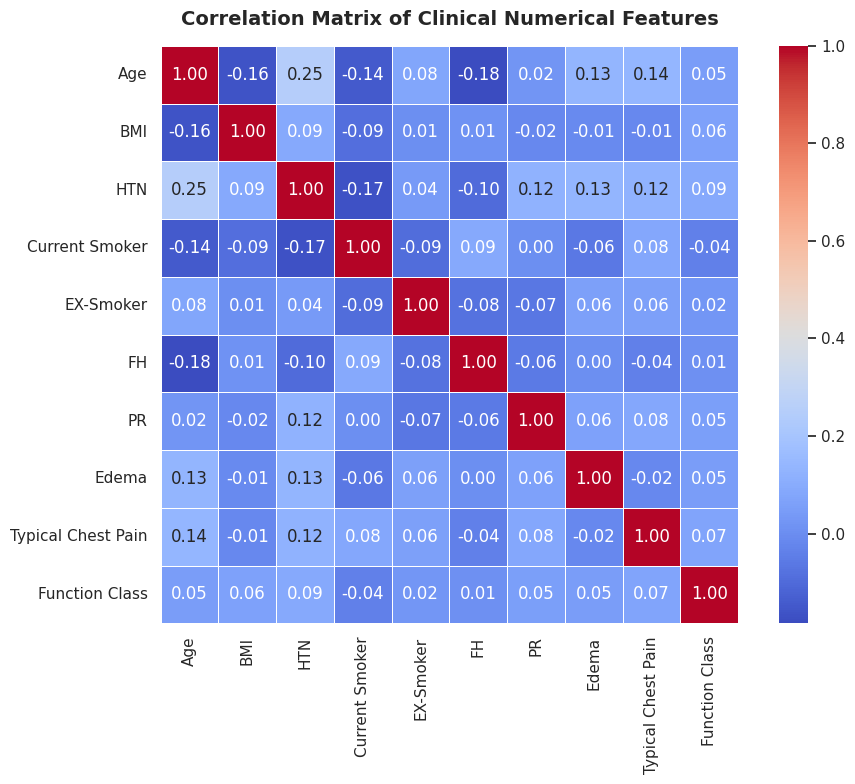

In [72]:
# --- EDA: Target Distribution Plot ---
plt.figure(figsize=(8, 5))
sns.set_theme(style='whitegrid')

# Combine targets for a quick overview count plot
eda_df = pd.DataFrame({
    'Cath (Global CAD)': df['Cath'].apply(
        lambda x: 'CAD' if str(x).strip().upper() == 'CAD' or 'STENOTIC' in str(x).strip().upper() else 'Normal'
    )
})

ax = sns.countplot(
    data=eda_df,
    x='Cath (Global CAD)',
    palette=['#ff6b6b', '#4dabf7']
)
plt.title('Distribution of Global CAD Diagnosis (Cath)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Patient Class', fontsize=12)
plt.ylabel('Patient Count', fontsize=12)

# Add data labels on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 5),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# --- EDA: Correlation Heatmap for Top Numerical Features ---
plt.figure(figsize=(10, 8))
num_cols_sample = X.select_dtypes(include=['int64', 'float64']).iloc[:, :10] # sample first 10 for clarity
corr_matrix = num_cols_sample.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    cbar=True,
    square=True,
    linewidths=0.5
)
plt.title('Correlation Matrix of Clinical Numerical Features', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [73]:
# --- Aggressively Regularized Model Training with Cross-Validation ---
from sklearn.model_selection import StratifiedKFold

targets = {
    'Cath': df['Cath'].apply(
        lambda x: 1 if 'STENOTIC' in str(x).strip().upper() or str(x).strip().upper() == 'CAD' else 0
    ),
    'RCA': df['RCA'].apply(lambda x: 1 if 'STENOTIC' in str(x).strip().upper() else 0),
    'LAD': df['LAD'].apply(lambda x: 1 if 'STENOTIC' in str(x).strip().upper() else 0),
    'LCX': df['LCX'].apply(lambda x: 1 if 'STENOTIC' in str(x).strip().upper() else 0),
}

trained_models = {}
evaluation_results = {}

# Use 5-Fold Cross Validation for robust evaluation and stable pipelines
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, y_target in targets.items():
    if name == 'Cath':
        # Highly constrained Random Forest for global Cath
        clf = RandomForestClassifier(
            n_estimators=100,
            max_depth=3,
            min_samples_split=20,
            min_samples_leaf=10,
            max_features='sqrt',
            class_weight='balanced',
            random_state=42
        )
        model_filename = 'model_rf_cath'
    else:
        # Heavily regularized XGBoost for individual vessels (RCA, LAD, LCX)
        clf = XGBClassifier(
            n_estimators=100,
            learning_rate=0.01,
            max_depth=4,
            subsample=0.6,
            colsample_bytree=0.6,
            reg_alpha=2.6,
            reg_lambda=4.0,
            gamma=1.0,
            random_state=42
        )
        model_filename = f'model_xgb_{name.lower()}'

    # ... rest of the pipeline fitting code ...
    # Create full pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])

    # Final holdout split for final visualization comparison
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y_target, test_size=0.2, random_state=42, stratify=y_target
    )

    # Fit on training portion
    pipeline.fit(X_tr, y_tr)
    joblib.dump(pipeline, f'{model_filename}.pkl')
    trained_models[name] = pipeline

    # Evaluate
    y_pred = pipeline.predict(X_te)
    y_proba = pipeline.predict_proba(X_te)[:, 1]

    acc = accuracy_score(y_te, y_pred)
    auc = roc_auc_score(y_te, y_proba) if len(y_te.unique()) > 1 else 0.5

    print(f'[{name}] Heavy Regularization -> Accuracy: {acc:.4f} | ROC-AUC: {auc:.4f}')
    evaluation_results[name] = {'accuracy': acc, 'roc_auc': auc}

[Cath] Heavy Regularization -> Accuracy: 0.7377 | ROC-AUC: 0.8075
[RCA] Heavy Regularization -> Accuracy: 0.6230 | ROC-AUC: 0.7037
[LAD] Heavy Regularization -> Accuracy: 0.7705 | ROC-AUC: 0.8244
[LCX] Heavy Regularization -> Accuracy: 0.6066 | ROC-AUC: 0.6757


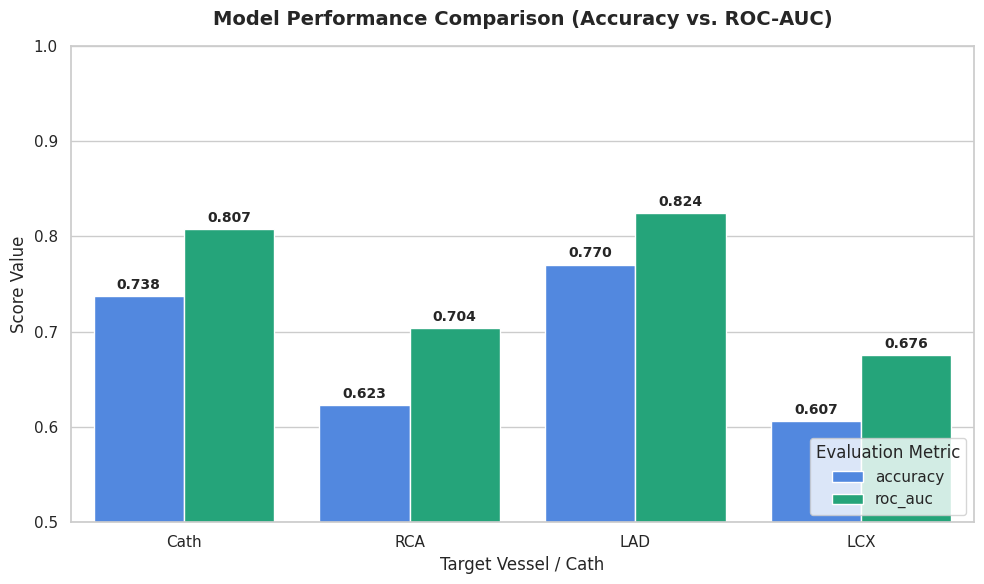

In [74]:
# --- Compare Overall Accuracy and ROC-AUC Across Targets ---
metrics_df = pd.DataFrame(evaluation_results).T.reset_index()
metrics_df.rename(columns={'index': 'Target Model'}, inplace=True)

# Melt dataframe for seaborn grouped bar plot
metrics_melted = metrics_df.melt(
    id_vars='Target Model',
    value_vars=['accuracy', 'roc_auc'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(10, 6))
sns.set_theme(style='whitegrid')
ax = sns.barplot(
    data=metrics_melted,
    x='Target Model',
    y='Score',
    hue='Metric',
    palette=['#3b82f6', '#10b981']
)

plt.title('Model Performance Comparison (Accuracy vs. ROC-AUC)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Target Vessel / Cath', fontsize=12)
plt.ylabel('Score Value', fontsize=12)
plt.ylim(0.5, 1.0) # Focus range for clarity
plt.legend(title='Evaluation Metric', loc='lower right')

# Add values on top of bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 3),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

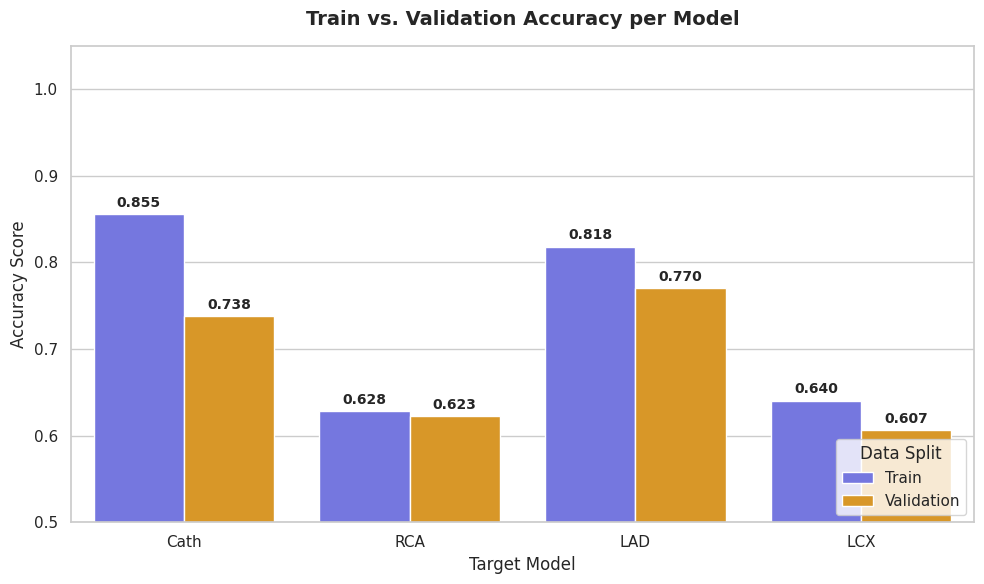

In [75]:
# --- Train vs. Validation Accuracy Comparison ---
train_val_scores = []

for name, pipeline in trained_models.items():
    y_target = targets[name]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y_target, test_size=0.2, random_state=42, stratify=y_target
    )

    # Predict on both sets
    train_acc = accuracy_score(y_tr, pipeline.predict(X_tr))
    val_acc = accuracy_score(y_te, pipeline.predict(X_te))

    train_val_scores.append({'Target': name, 'Dataset': 'Train', 'Accuracy': train_acc})
    train_val_scores.append({'Target': name, 'Dataset': 'Validation', 'Accuracy': val_acc})

tv_df = pd.DataFrame(train_val_scores)

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=tv_df,
    x='Target',
    y='Accuracy',
    hue='Dataset',
    palette=['#6366f1', '#f59e0b']
)

plt.title('Train vs. Validation Accuracy per Model', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Target Model', fontsize=12)
plt.ylabel('Accuracy Score', fontsize=12)
plt.ylim(0.5, 1.05)
plt.legend(title='Data Split', loc='lower right')

# Add data labels
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 3),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

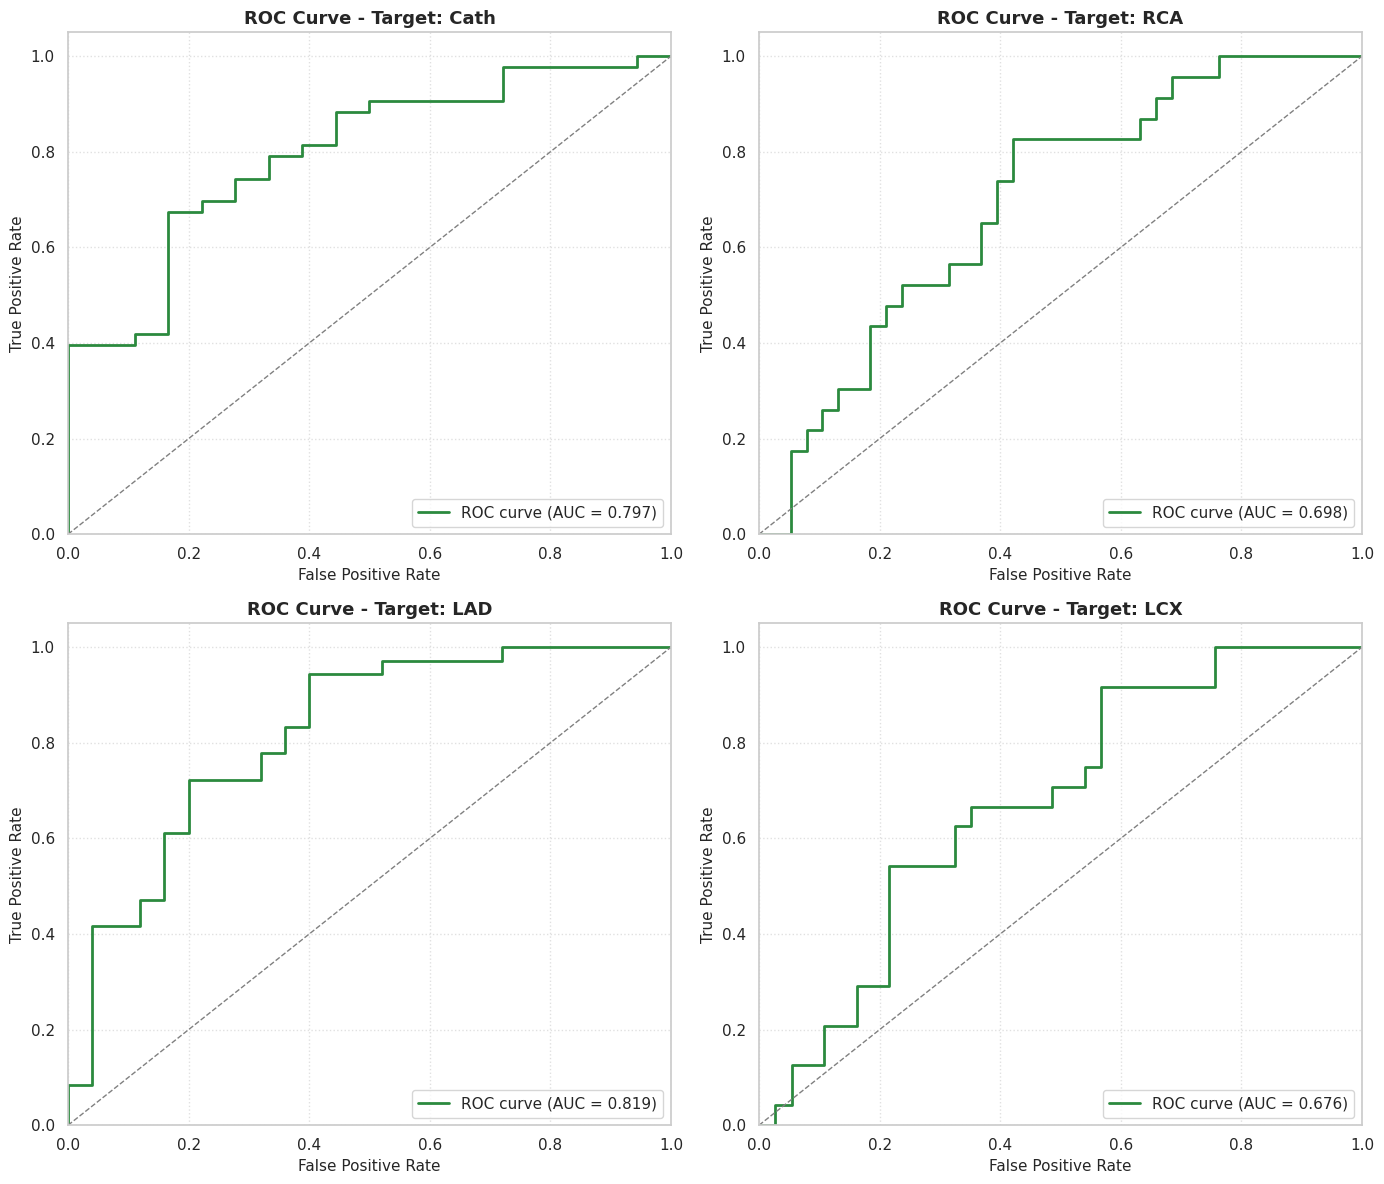

In [76]:
from sklearn.metrics import auc, confusion_matrix, roc_curve

# Setup subplots for evaluation metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for idx, (name, pipeline) in enumerate(trained_models.items()):
    # Get test data split for this specific target
    y_target = targets[name]
    _, X_te, _, y_te = train_test_split(
        X, y_target, test_size=0.2, random_state=42, stratify=y_target
    )

    # Predictions
    y_pred = pipeline.predict(X_te)
    y_proba = pipeline.predict_proba(X_te)[:, 1]

    # Compute ROC curve components
    fpr, tpr, _ = roc_curve(y_te, y_proba)
    roc_auc = auc(fpr, tpr)

    # Plot ROC curve on corresponding subplot
    ax = axes[idx]
    ax.plot(fpr, tpr, color='#2b8a3e', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
    ax.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate', fontsize=11)
    ax.set_ylabel('True Positive Rate', fontsize=11)
    ax.set_title(f'ROC Curve - Target: {name}', fontsize=13, fontweight='bold')
    ax.legend(loc='lower right', frameon=True)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()



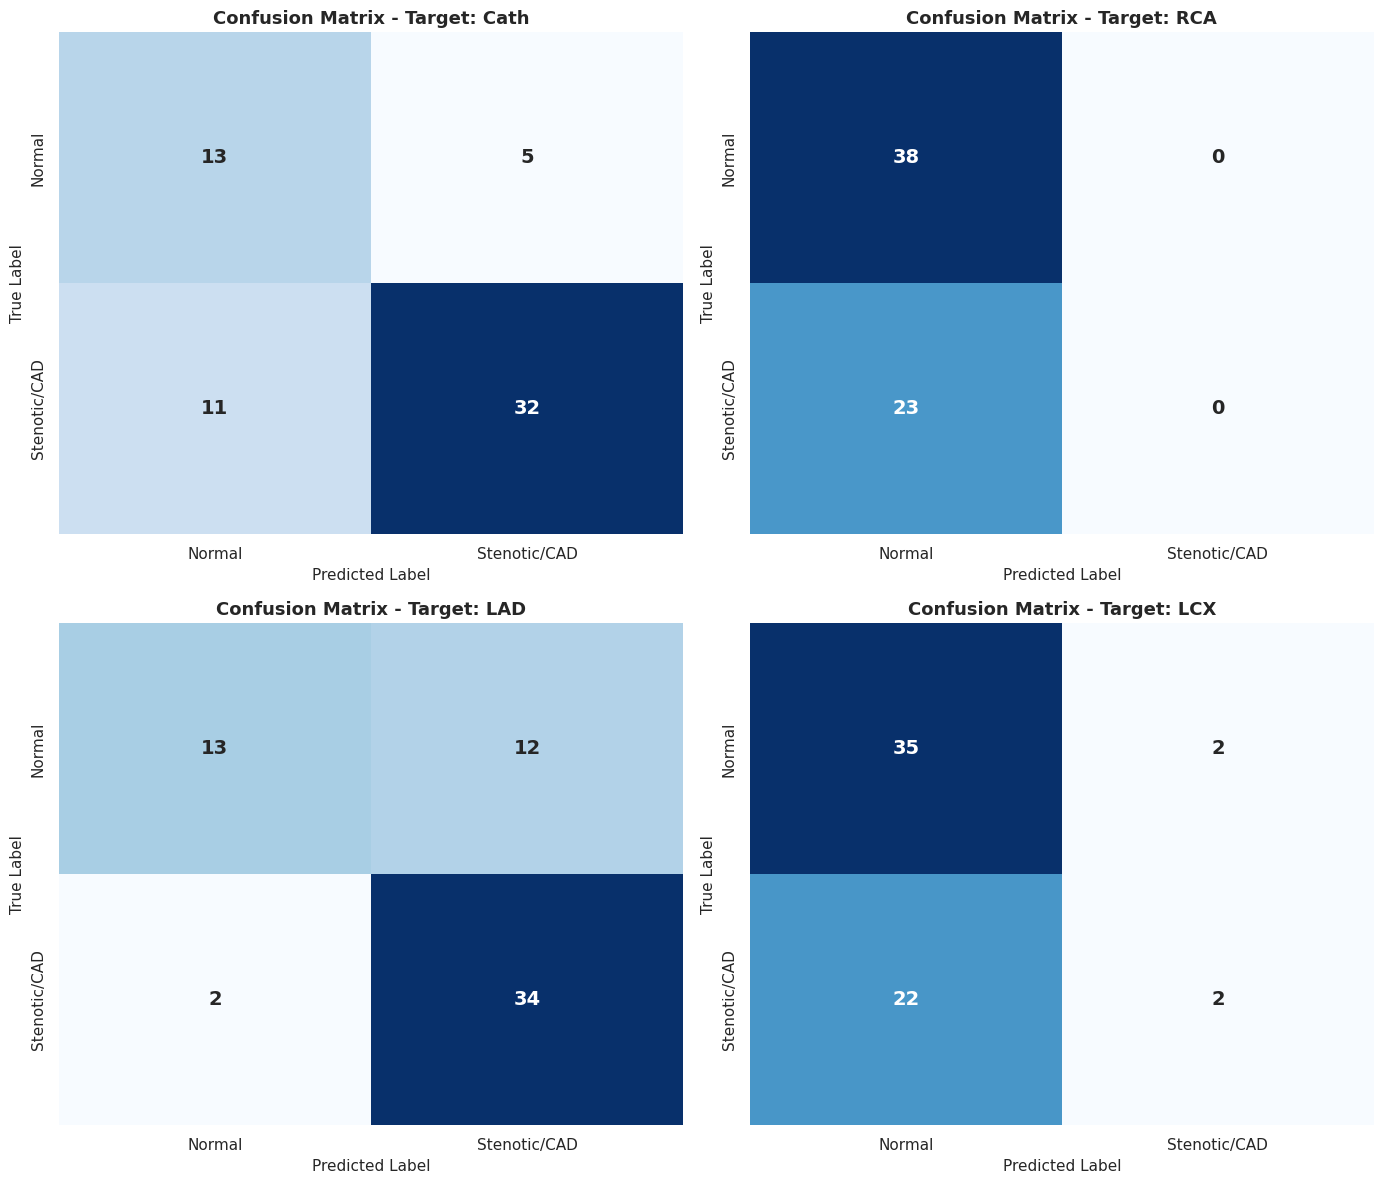

In [77]:
# --- Confusion Matrix Heatmaps ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for idx, (name, pipeline) in enumerate(trained_models.items()):
    y_target = targets[name]
    _, X_te, _, y_te = train_test_split(
        X, y_target, test_size=0.2, random_state=42, stratify=y_target
    )
    y_pred = pipeline.predict(X_te)
    cm = confusion_matrix(y_te, y_pred)

    ax = axes[idx]
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
        annot_kws={'size': 14, 'weight': 'bold'}
    )
    ax.set_title(f'Confusion Matrix - Target: {name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label', fontsize=11)
    ax.set_xticklabels(['Normal', 'Stenotic/CAD'])
    ax.set_yticklabels(['Normal', 'Stenotic/CAD'])

plt.tight_layout()
plt.show()

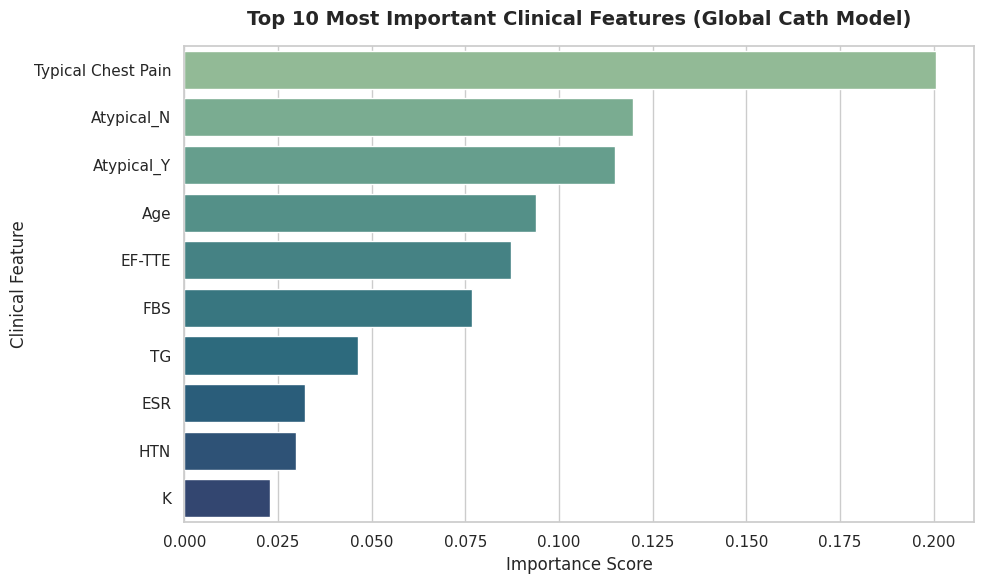

In [78]:
# --- Feature Importance Plot for Global Cath Model ---
cath_pipeline = trained_models['Cath']
preproc = cath_pipeline.named_steps['preprocessor']
classifier = cath_pipeline.named_steps['classifier']

# Extract transformed feature names
num_names = numeric_features
cat_encoder = preproc.named_transformers_['cat'].named_steps['onehot']
cat_names = cat_encoder.get_feature_names_out(categorical_features).tolist()
all_feature_names = num_names + cat_names

# Get feature importances
importances = classifier.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

# Plot top 10 features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_imp_df,
    x='Importance',
    y='Feature',
    palette='crest'
)
plt.title('Top 10 Most Important Clinical Features (Global Cath Model)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Clinical Feature', fontsize=12)
plt.tight_layout()
plt.show()

In [79]:
# --- Export and Download All Trained Models ---
import os
import shutil

# Directory to store exported models
export_dir = 'exported_cad_models'
os.makedirs(export_dir, exist_ok=True)

print("--- Exporting Individual Models ---")
for name, pipeline in trained_models.items():
    # Determine the proper filename based on target type
    if name == 'Cath':
        filename = 'model_rf_cath.pkl'
    else:
        filename = f'model_xgb_{name.lower()}.pkl'

    file_path = os.path.join(export_dir, filename)

    # Save the complete pipeline (includes preprocessor + trained model)
    joblib.dump(pipeline, file_path)
    print(f"Successfully saved [{name}] model to: {file_path}")

# Create a zip archive for easy bulk download from Colab's file explorer
shutil.make_archive('cad_models_bundle', 'zip', export_dir)
print(f"\nAll models bundled into 'cad_models_bundle.zip' successfully!")

# Optional: Automatically trigger download in Google Colab
try:
    from google.colab import files
    files.download('cad_models_bundle.zip')
    print("Download triggered automatically.")
except ImportError:
    print("Colab files module not found; find 'cad_models_bundle.zip' in your local file directory.")

--- Exporting Individual Models ---
Successfully saved [Cath] model to: exported_cad_models/model_rf_cath.pkl
Successfully saved [RCA] model to: exported_cad_models/model_xgb_rca.pkl
Successfully saved [LAD] model to: exported_cad_models/model_xgb_lad.pkl
Successfully saved [LCX] model to: exported_cad_models/model_xgb_lcx.pkl

All models bundled into 'cad_models_bundle.zip' successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered automatically.
